# IS 362 — Preprocessing Data for scikit-learn

**Dataset:** [UCI Mushroom Dataset](https://archive.ics.uci.edu/dataset/73/mushroom)  
**Goal:** Prepare selected mushroom attributes as numeric features for Project 4 and explore their relationships to edibility.

The data contains categorical mushroom characteristics. We use **class**, **odor**, and **bruises**.

## 1. Import libraries and load the original data

The code reads the original dataset directly from the UCI repository, so a separate local data file is not required. An internet connection is needed the first time you run it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"
column_names = [
    "class", "cap-shape", "cap-surface", "cap-color", "bruises", "odor",
    "gill-attachment", "gill-spacing", "gill-size", "gill-color",
    "stalk-shape", "stalk-root", "stalk-surface-above-ring",
    "stalk-surface-below-ring", "stalk-color-above-ring",
    "stalk-color-below-ring", "veil-type", "veil-color", "ring-number",
    "ring-type", "spore-print-color", "population", "habitat"
]
raw = pd.read_csv(DATA_URL, header=None, names=column_names)
print("Original dataset shape:", raw.shape)
display(raw.head())

Original dataset shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


## 2. Data dictionary and selected columns

According to the [UCI dataset description](https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.names):

- **class:** `e` = edible, `p` = poisonous.
- **odor:** `a` = almond, `l` = anise, `c` = creosote, `y` = fishy, `f` = foul, `m` = musty, `n` = none, `p` = pungent, `s` = spicy.
- **bruises:** `t` = bruises, `f` = no bruises.

We select these columns and give the target a meaningful name.

In [2]:
mushrooms = raw[["class", "odor", "bruises"]].copy()
mushrooms.columns = ["poisonous", "odor", "bruises"]
print("Missing values in selected columns:")
print(mushrooms.isna().sum())
print("Original category distributions:")
for column in mushrooms.columns:
    print(f"\n{column}:")
    print(mushrooms[column].value_counts().sort_index())

Missing values in selected columns:
poisonous    0
odor         0
bruises      0
dtype: int64
Original category distributions:

poisonous:
poisonous
e    4208
p    3916
Name: count, dtype: int64

odor:
odor
a     400
c     192
f    2160
l     400
m      36
n    3528
p     256
s     576
y     576
Name: count, dtype: int64

bruises:
bruises
f    4748
t    3376
Name: count, dtype: int64


## 3. Convert categorical codes to numeric values

The mappings are explicit so the same codes will have the same meaning when reused in Project 4. These integers are **category labels**, not meaningful numerical distances. For models that assume continuous or ordered predictors, consider one-hot encoding odor in Project 4.

In [3]:
class_map = {"e": 0, "p": 1}
odor_map = {"a": 0, "l": 1, "c": 2, "y": 3, "f": 4,
            "m": 5, "n": 6, "p": 7, "s": 8}
bruises_map = {"f": 0, "t": 1}

mushrooms["poisonous"] = mushrooms["poisonous"].map(class_map)
mushrooms["odor"] = mushrooms["odor"].map(odor_map)
mushrooms["bruises"] = mushrooms["bruises"].map(bruises_map)

assert mushrooms.notna().all().all(), "Unexpected categorical code detected."
mushrooms = mushrooms.astype(int)
print("Numeric dataset:")
display(mushrooms.head())
print("Data types:")
print(mushrooms.dtypes)
print("Rows and columns:", mushrooms.shape)

Numeric dataset:


,poisonous,odor,bruises
0,1,7,1
1,0,0,1
2,0,1,1
3,1,7,1
4,0,6,0


Data types:
poisonous    int64
odor         int64
bruises      int64
dtype: object
Rows and columns: (8124, 3)


## 4. Exploratory data analysis: distribution of each column

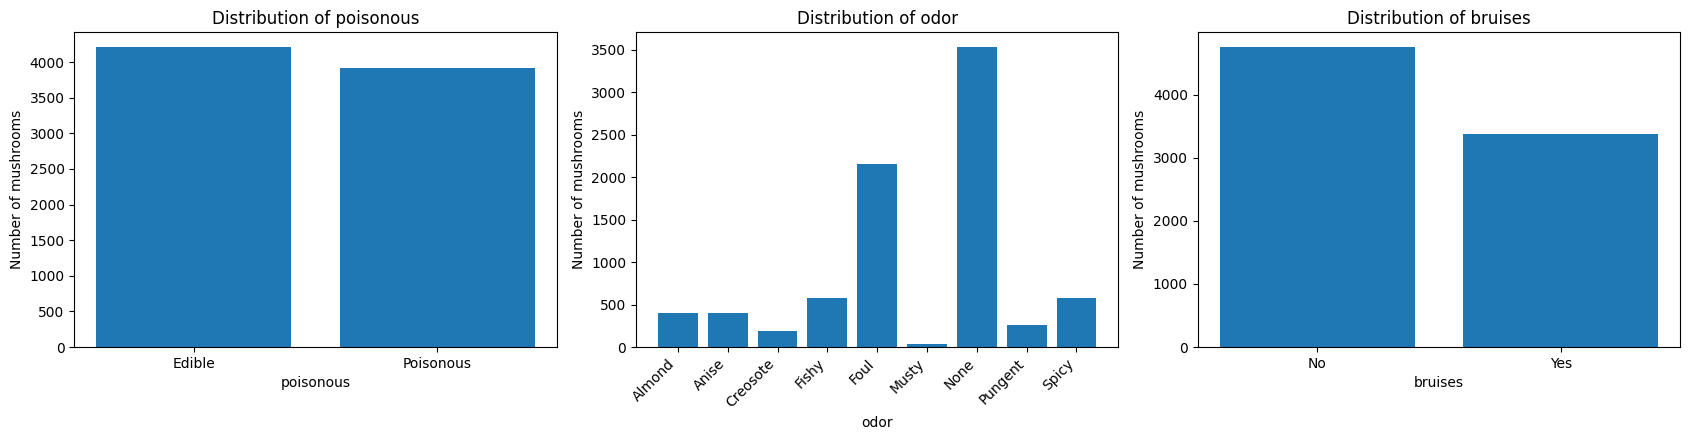


poisonous distribution:


,Category,Count,Percent
0,Edible,4208,51.8
1,Poisonous,3916,48.2



odor distribution:


,Category,Count,Percent
0,Almond,400,4.9
1,Anise,400,4.9
2,Creosote,192,2.4
3,Fishy,576,7.1
4,Foul,2160,26.6
5,Musty,36,0.4
6,None,3528,43.4
7,Pungent,256,3.2
8,Spicy,576,7.1



bruises distribution:


,Category,Count,Percent
0,No,4748,58.4
1,Yes,3376,41.6


In [4]:
labels = {
    "poisonous": {0: "Edible", 1: "Poisonous"},
    "odor": {0: "Almond", 1: "Anise", 2: "Creosote", 3: "Fishy",
             4: "Foul", 5: "Musty", 6: "None", 7: "Pungent", 8: "Spicy"},
    "bruises": {0: "No", 1: "Yes"}
}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, column in zip(axes, mushrooms.columns):
    counts = mushrooms[column].value_counts().sort_index()
    ax.bar(range(len(counts)), counts.values)
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels([labels[column][v] for v in counts.index],
                       rotation=45 if column == "odor" else 0, ha="right" if column == "odor" else "center")
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of mushrooms")
plt.tight_layout()
plt.show()

for column in mushrooms.columns:
    print(f"\n{column} distribution:")
    counts = mushrooms[column].value_counts().sort_index()
    display(pd.DataFrame({"Category": [labels[column][x] for x in counts.index],
                          "Count": counts.values,
                          "Percent": (100 * counts.values / len(mushrooms)).round(1)}))

## 5. Scatterplots: edible/poisonous vs. odor and bruises

Since both axes represent discrete categories, many points overlap. Small reproducible random jitter makes overlapping observations easier to see; it does **not** change the underlying data.

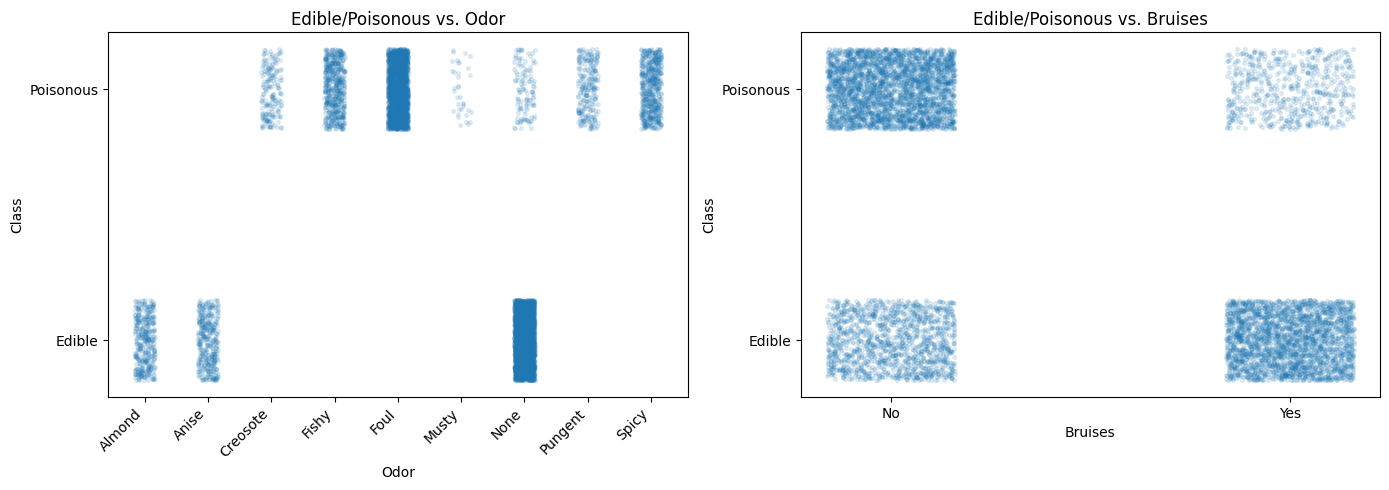

In [5]:
rng = np.random.default_rng(362)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, feature in zip(axes, ["odor", "bruises"]):
    x = mushrooms[feature].to_numpy() + rng.uniform(-0.16, 0.16, len(mushrooms))
    y = mushrooms["poisonous"].to_numpy() + rng.uniform(-0.16, 0.16, len(mushrooms))
    ax.scatter(x, y, s=7, alpha=0.12)
    ax.set_xticks(list(labels[feature].keys()))
    ax.set_xticklabels(list(labels[feature].values()), rotation=45 if feature == "odor" else 0,
                       ha="right" if feature == "odor" else "center")
    ax.set_yticks([0, 1], ["Edible", "Poisonous"])
    ax.set_xlabel(feature.title())
    ax.set_ylabel("Class")
    ax.set_title(f"Edible/Poisonous vs. {feature.title()}")
plt.tight_layout()
plt.show()

## 6. Compare the poisonous percentage within each category

These summary tables help interpret the scatterplots more clearly.

In [6]:
for feature in ["odor", "bruises"]:
    summary = mushrooms.groupby(feature)["poisonous"].agg(
        mushroom_count="size", poisonous_count="sum", poisonous_rate="mean"
    )
    summary.index = [labels[feature][v] for v in summary.index]
    summary["poisonous_rate"] = (100 * summary["poisonous_rate"]).round(1)
    summary = summary.rename(columns={"poisonous_rate": "poisonous_percent"})
    print(f"\nPoisonous percentage by {feature}:")
    display(summary)


Poisonous percentage by odor:


,mushroom_count,poisonous_count,poisonous_percent
Almond,400,0,0.0
Anise,400,0,0.0
Creosote,192,192,100.0
Fishy,576,576,100.0
Foul,2160,2160,100.0
Musty,36,36,100.0
None,3528,120,3.4
Pungent,256,256,100.0
Spicy,576,576,100.0



Poisonous percentage by bruises:


,mushroom_count,poisonous_count,poisonous_percent
No,4748,3292,69.3
Yes,3376,624,18.5


## 7. Preliminary conclusions

**Odor** appears to be a strong predictor of whether a mushroom is edible or poisonous. In this dataset, several odor categories are associated predominantly or exclusively with one class, so odor is likely useful for a predictive classifier.

**Bruises** also appears to contain predictive information, but both edible and poisonous mushrooms can share the same bruising status. It is therefore less decisive on its own than odor. Combining features may help a classifier distinguish cases where one feature is ambiguous.

**Limitations:** These observations describe patterns in this historical benchmark dataset, not a validated real-world method for identifying safe mushrooms. Never use a model or odor/bruising alone to decide whether a wild mushroom is safe to eat. Model performance must be assessed on held-out data in Project 4.

## 8. Save prepared data for Project 4

Run this cell to create a numeric CSV in the same folder as the notebook.

In [7]:
mushrooms.to_csv("mushrooms_preprocessed.csv", index=False)
print("Saved mushrooms_preprocessed.csv")
display(mushrooms.head())

Saved mushrooms_preprocessed.csv


,poisonous,odor,bruises
0,1,7,1
1,0,0,1
2,0,1,1
3,1,7,1
4,0,6,0


## Sources

- UCI Machine Learning Repository. [Mushroom dataset](https://archive.ics.uci.edu/dataset/73/mushroom).
- UCI Machine Learning Repository. [Original attribute descriptions / data dictionary](https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.names).
- UCI Machine Learning Repository. [Original data file](https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data).